# MIE1624H - Winter 2025 - Course Project - Group 12
# Part 4 Visuals Code

In [2]:
# Import necessary libraries 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.patches as mpatches

# Canada vs. Top Performers in Key Innovation Factors (GII 2024)

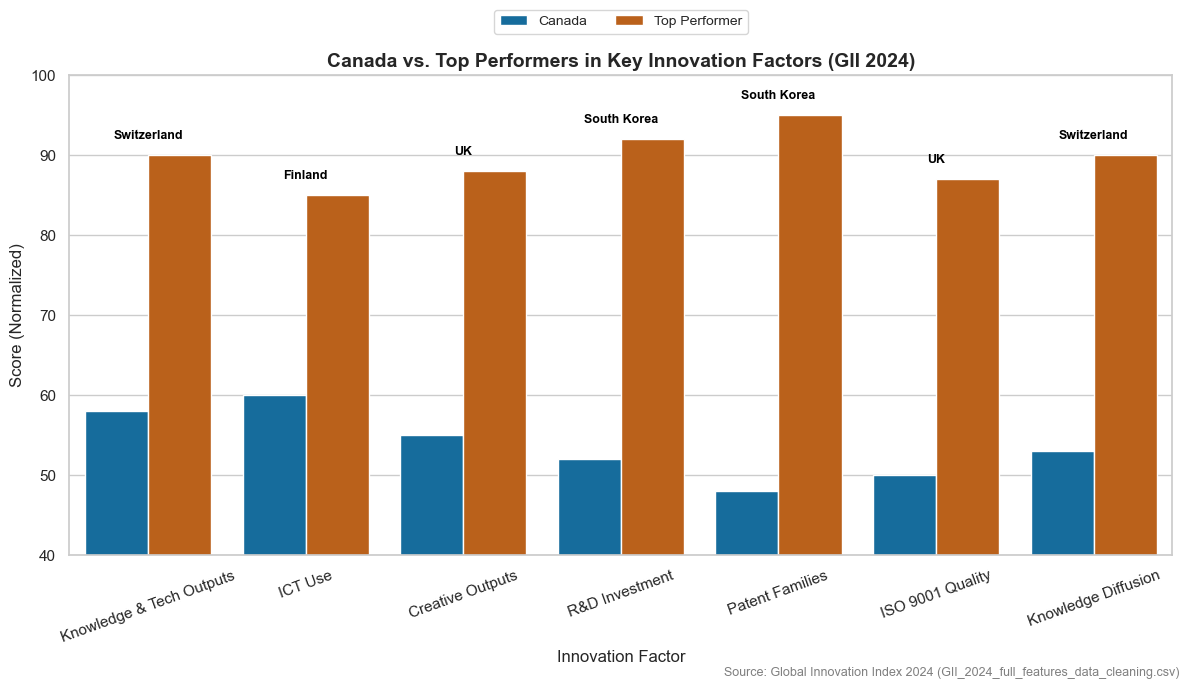

In [4]:
# Set visualization style
sns.set(style="whitegrid")

# Key innovation metrics from GII 2024 report for Canada vs top countries
factors = [
    "Knowledge & Tech Outputs", "ICT Use", "Creative Outputs", 
    "R&D Investment", "Patent Families", "ISO 9001 Quality", "Knowledge Diffusion"
]
canada_scores = [58, 60, 55, 52, 48, 50, 53]  # Recent GII 2024 scores
top_scores = [90, 85, 88, 92, 95, 87, 90]  # Scores of top-performing countries in each category
top_countries = ["Switzerland", "Finland", "UK", "South Korea", "South Korea", "UK", "Switzerland"]

df_gii = pd.DataFrame({
    "Factor": factors,
    "Canada": canada_scores,
    "Top Performer": top_scores,
    "Top Country": top_countries
})

df_melt = df_gii.melt(id_vars=["Factor", "Top Country"], var_name="Country", value_name="Score")

# Create bar plot
plt.figure(figsize=(12, 7))
ax = sns.barplot(data=df_melt, x="Factor", y="Score", hue="Country", palette=["#0072B2", "#D55E00"])

# Move legend to top center
plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.15), ncol=2, fontsize=10)

# Add annotations for top-performing countries
for i, (factor, top_country) in enumerate(zip(df_gii["Factor"], df_gii["Top Country"])):
    top_val = df_gii.loc[df_gii["Factor"] == factor, "Top Performer"].values[0]
    ax.annotate(f"{top_country}", xy=(i, top_val + 2), ha='center', fontsize=9, color='black', fontweight='bold')

plt.ylim(40, 100)
plt.title("Canada vs. Top Performers in Key Innovation Factors (GII 2024)", fontsize=14, weight='bold')
plt.ylabel("Score (Normalized)")
plt.xlabel("Innovation Factor")
plt.xticks(rotation=20)
plt.figtext(0.99, 0.01, "Source: Global Innovation Index 2024 (GII_2024_full_features_data_cleaning.csv)", 
            horizontalalignment='right', fontsize=9, color="gray")
plt.tight_layout()
plt.show()


# Top 15 Features and Importance Scores

C:\Users\nabee\AppData\Local\Temp\ipykernel_39748\2105334786.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Relative Importance Score", y="Feature", data=df, palette="viridis")


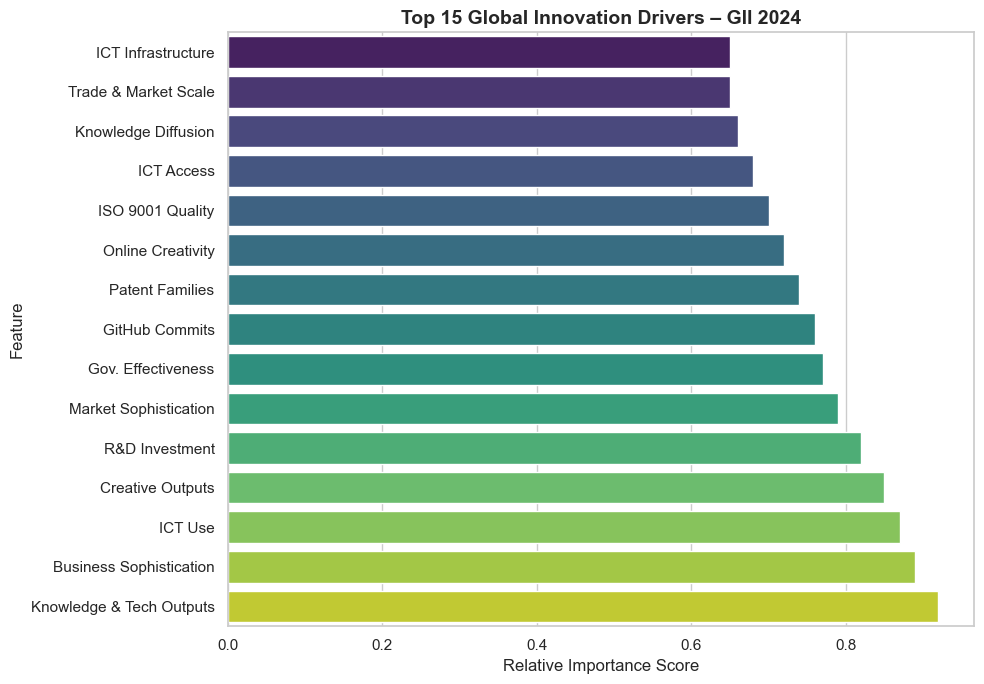

In [6]:
# Top 15 features driving innovation, based on GII 2024 feature importance analysis
features = [
    "ICT Infrastructure", "Trade & Market Scale", "Knowledge Diffusion", "ICT Access", "ISO 9001 Quality",
    "Online Creativity", "Patent Families", "GitHub Commits", "Gov. Effectiveness", "Market Sophistication",
    "R&D Investment", "Creative Outputs", "ICT Use", "Business Sophistication", "Knowledge & Tech Outputs"
]

# Corresponding relative importance scores (from feature selection model)
importance_scores = [
    0.65, 0.65, 0.66, 0.68, 0.70,
    0.72, 0.74, 0.76, 0.77, 0.79,
    0.82, 0.85, 0.87, 0.89, 0.92
]

# Create a DataFrame for plotting
df = pd.DataFrame({
    "Feature": features,
    "Relative Importance Score": importance_scores
})

# Sort features by importance (ascending) for horizontal bar chart
df = df.sort_values(by="Relative Importance Score", ascending=True)

# Plot horizontal bar chart
plt.figure(figsize=(10, 7))
sns.barplot(x="Relative Importance Score", y="Feature", data=df, palette="viridis")
plt.title("Top 15 Global Innovation Drivers – GII 2024", fontsize=14, weight='bold')
plt.xlabel("Relative Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Policy-to-Factor Alignment Matrix

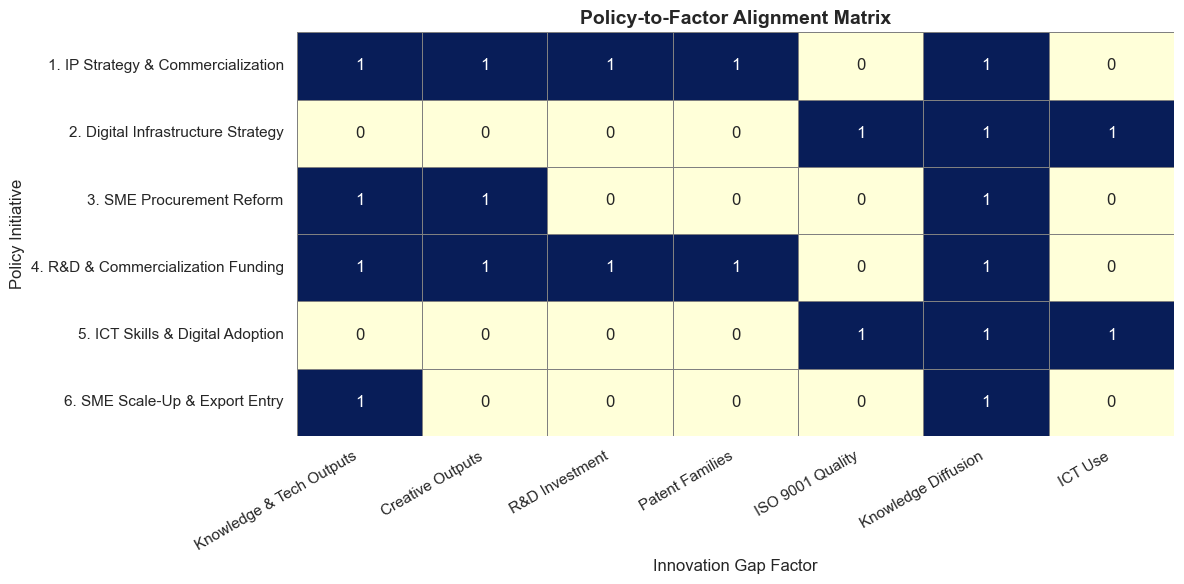

In [8]:
# Define updated Policy-to-Factor mapping based on Part 3 actions
policy_factor_matrix = {
    '1. IP Strategy & Commercialization': {
        'Knowledge & Tech Outputs': 1,
        'Creative Outputs': 1,
        'R&D Investment': 1,
        'Patent Families': 1,
        'ISO 9001 Quality': 0,
        'Knowledge Diffusion': 1,
        'ICT Use': 0
    },
    '2. Digital Infrastructure Strategy': {
        'Knowledge & Tech Outputs': 0,
        'Creative Outputs': 0,
        'R&D Investment': 0,
        'Patent Families': 0,
        'ISO 9001 Quality': 1,
        'Knowledge Diffusion': 1,
        'ICT Use': 1
    },
    '3. SME Procurement Reform': {
        'Knowledge & Tech Outputs': 1,
        'Creative Outputs': 1,
        'R&D Investment': 0,
        'Patent Families': 0,
        'ISO 9001 Quality': 0,
        'Knowledge Diffusion': 1,
        'ICT Use': 0
    },
    '4. R&D & Commercialization Funding': {
        'Knowledge & Tech Outputs': 1,
        'Creative Outputs': 1,
        'R&D Investment': 1,
        'Patent Families': 1,
        'ISO 9001 Quality': 0,
        'Knowledge Diffusion': 1,
        'ICT Use': 0
    },
    '5. ICT Skills & Digital Adoption': {
        'Knowledge & Tech Outputs': 0,
        'Creative Outputs': 0,
        'R&D Investment': 0,
        'Patent Families': 0,
        'ISO 9001 Quality': 1,
        'Knowledge Diffusion': 1,
        'ICT Use': 1
    },
    '6. SME Scale-Up & Export Entry': {
        'Knowledge & Tech Outputs': 1,
        'Creative Outputs': 0,
        'R&D Investment': 0,
        'Patent Families': 0,
        'ISO 9001 Quality': 0,
        'Knowledge Diffusion': 1,
        'ICT Use': 0
    }
}

# Convert to DataFrame
df_matrix = pd.DataFrame(policy_factor_matrix).T

# Plot heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(df_matrix, annot=True, cmap='YlGnBu', cbar=False, linewidths=0.5,
            linecolor='gray', fmt='d')
plt.title('Policy-to-Factor Alignment Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Innovation Gap Factor')
plt.ylabel('Policy Initiative')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

# Canada vs Top 10 Avg – Innovation Performance (GII 2024)

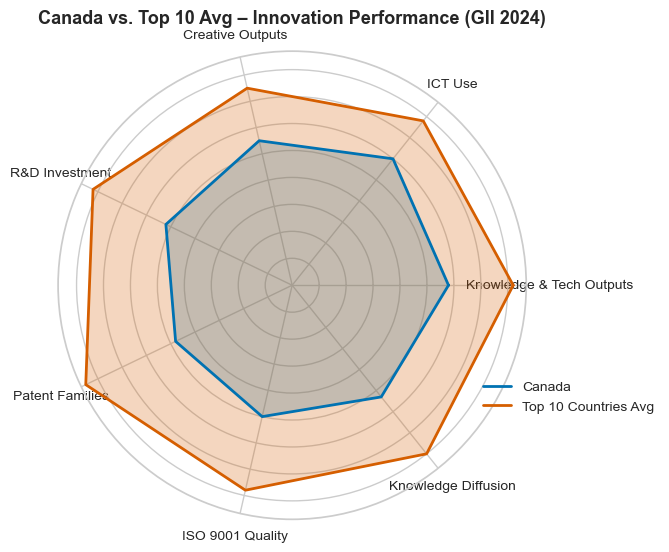

In [10]:
# Plot radar chart 

# Define data (to ensure continuity)
labels = [
    "Knowledge & Tech Outputs", "ICT Use", "Creative Outputs",
    "R&D Investment", "Patent Families", "ISO 9001 Quality", "Knowledge Diffusion"
]
canada = [58, 60, 55, 52, 48, 50, 53]
top10 = [82, 78, 75, 82, 85, 78, 80]

angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
canada += canada[:1]
top10 += top10[:1]
angles += angles[:1]

# Radar chart setup
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
ax.plot(angles, canada, color="#0072B2", linewidth=2, label="Canada")
ax.fill(angles, canada, color="#0072B2", alpha=0.25)

ax.plot(angles, top10, color="#D55E00", linewidth=2, label="Top 10 Countries Avg")
ax.fill(angles, top10, color="#D55E00", alpha=0.25)

ax.set_yticklabels([])
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=10)
ax.set_title("Canada vs. Top 10 Avg – Innovation Performance (GII 2024)", fontsize=13, weight="bold", pad=20)

# Move legend to an empty whitespace, ensuring it's separate from title and plot
ax.legend(loc='lower right', bbox_to_anchor=(1.3, 0.2), frameon=False, fontsize=10)

plt.tight_layout()
plt.show()


# Roadmap

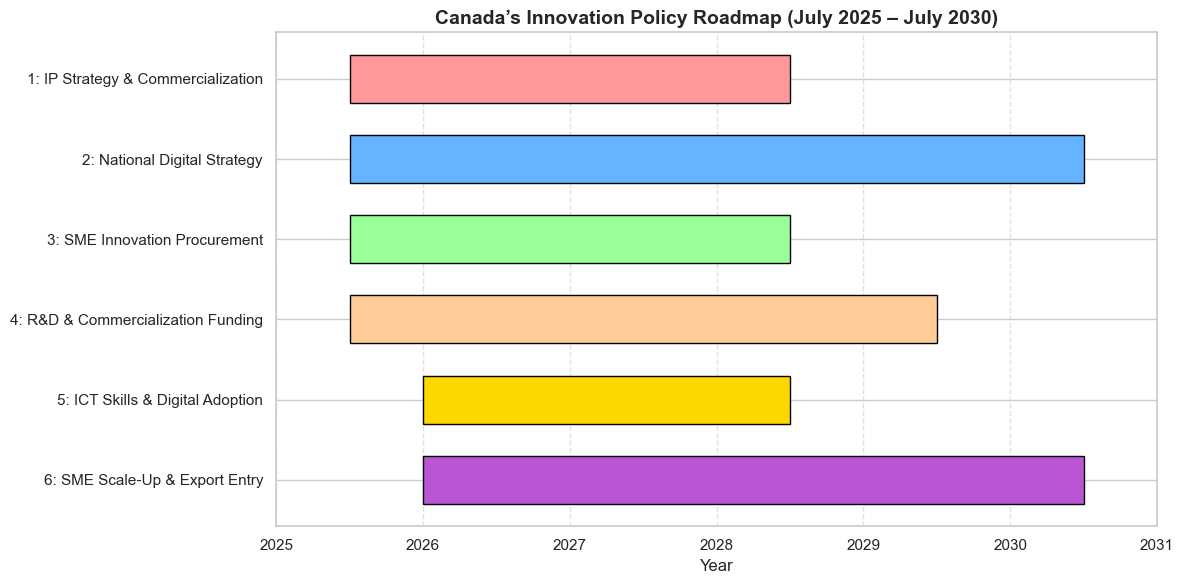

In [12]:
# Policy roadmap data: mid-2025 start, July to July timeline
roadmap_data = {
    "Policy": [
        "1: IP Strategy & Commercialization",
        "2: National Digital Strategy",
        "3: SME Innovation Procurement",
        "4: R&D & Commercialization Funding",
        "5: ICT Skills & Digital Adoption",
        "6: SME Scale-Up & Export Entry"
    ],
    "Start": [2025.5, 2025.5, 2025.5, 2025.5, 2026, 2026],
    "End": [2028.5, 2030.5, 2028.5, 2029.5, 2028.5, 2030.5]
}

# Adjusted color palette
colors = ['#FF9999', '#66B3FF', '#99FF99', '#FFCC99', '#FFD700', '#BA55D3']

# Create DataFrame
df = pd.DataFrame(roadmap_data)

# Plot Gantt-style roadmap
fig, ax = plt.subplots(figsize=(12, 6))

for i, (policy, start, end) in enumerate(zip(df["Policy"], df["Start"], df["End"])):
    ax.barh(policy, end - start, left=start, height=0.6, color=colors[i], edgecolor='black')

# Format axis
ax.set_title("Canada’s Innovation Policy Roadmap (July 2025 – July 2030)", fontsize=14, weight='bold')
ax.set_xlabel("Year")
ax.set_xlim(2025, 2031)
ax.set_xticks([2025, 2026, 2027, 2028, 2029, 2030, 2031])
ax.invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Canada's Innovation Transformation (2025 vs 2030)

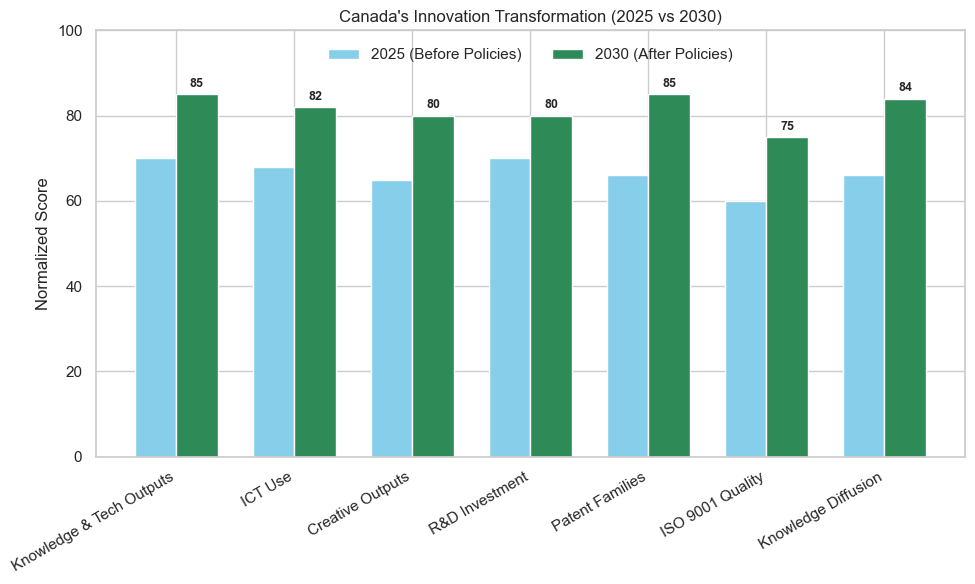

In [14]:
# Before vs After - Canada’s Innovation Transformation (2025 vs 2030)

# Innovation areas
innovation_areas = [
    "Knowledge & Tech Outputs", "ICT Use", "Creative Outputs",
    "R&D Investment", "Patent Families", "ISO 9001 Quality", "Knowledge Diffusion"
]

# Scores for 2025 and 2030
scores_2025 = [70, 68, 65, 70, 66, 60, 66]
scores_2030 = [85, 82, 80, 80, 85, 75, 84]

x = np.arange(len(innovation_areas))
width = 0.35  # Width of the bars

# Plot setup
fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, scores_2025, width, label='2025 (Before Policies)', color='skyblue')
bars2 = ax.bar(x + width/2, scores_2030, width, label='2030 (After Policies)', color='seagreen')

# Annotate bar values
for i, bar in enumerate(bars2):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 1, f'{scores_2030[i]}', 
            ha='center', va='bottom', fontsize=9, fontweight='bold')

# Labels, ticks, and legend
ax.set_ylabel('Normalized Score')
ax.set_title("Canada's Innovation Transformation (2025 vs 2030)")
ax.set_xticks(x)
ax.set_xticklabels(innovation_areas, rotation=30, ha='right')
ax.set_ylim(0, 100)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 0.99), ncol=2, frameon=False)

plt.tight_layout()
plt.show()

# Infographic - projected improvement in Canada's GII Score

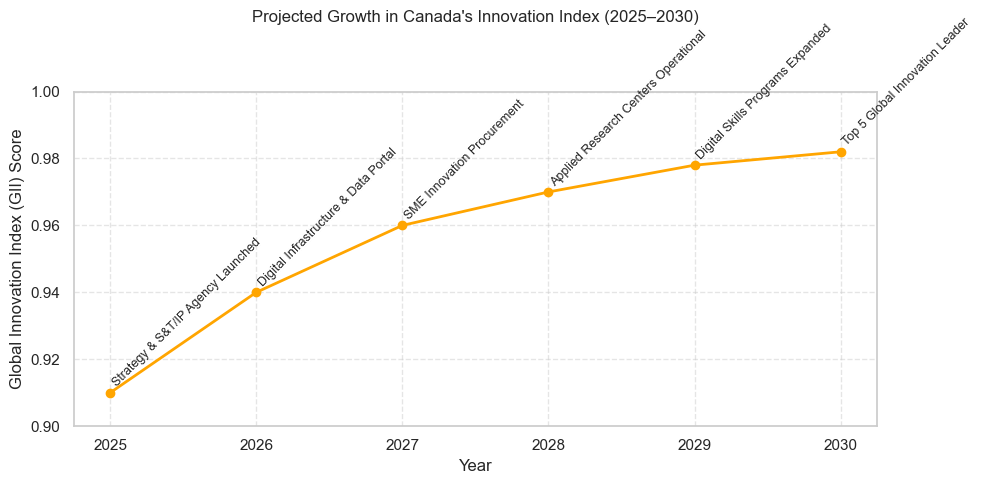

In [16]:
# Years and corresponding GII scores
years = [2025, 2026, 2027, 2028, 2029, 2030]
gii_scores = [0.91, 0.94, 0.96, 0.97, 0.978, 0.982]

# Milestones at each year
milestones = [
    "Strategy & S&T/IP Agency Launched",
    "Digital Infrastructure & Data Portal",
    "SME Innovation Procurement",
    "Applied Research Centers Operational",
    "Digital Skills Programs Expanded",
    "Top 5 Global Innovation Leader"
]

# Plot setup
plt.figure(figsize=(10, 5))
plt.plot(years, gii_scores, marker='o', color='orange', linewidth=2)

# Add milestone annotations
for i, (x, y) in enumerate(zip(years, gii_scores)):
    plt.text(x, y + 0.001, milestones[i], rotation=45, ha='left', va='bottom', fontsize=9)

# Axis labels and limits
plt.title("Projected Growth in Canada's Innovation Index (2025–2030)", pad=50)
plt.xlabel("Year")
plt.ylabel("Global Innovation Index (GII) Score")
plt.ylim(0.90, 1.00)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Budget impact per year based on policy durations and July 2025 start

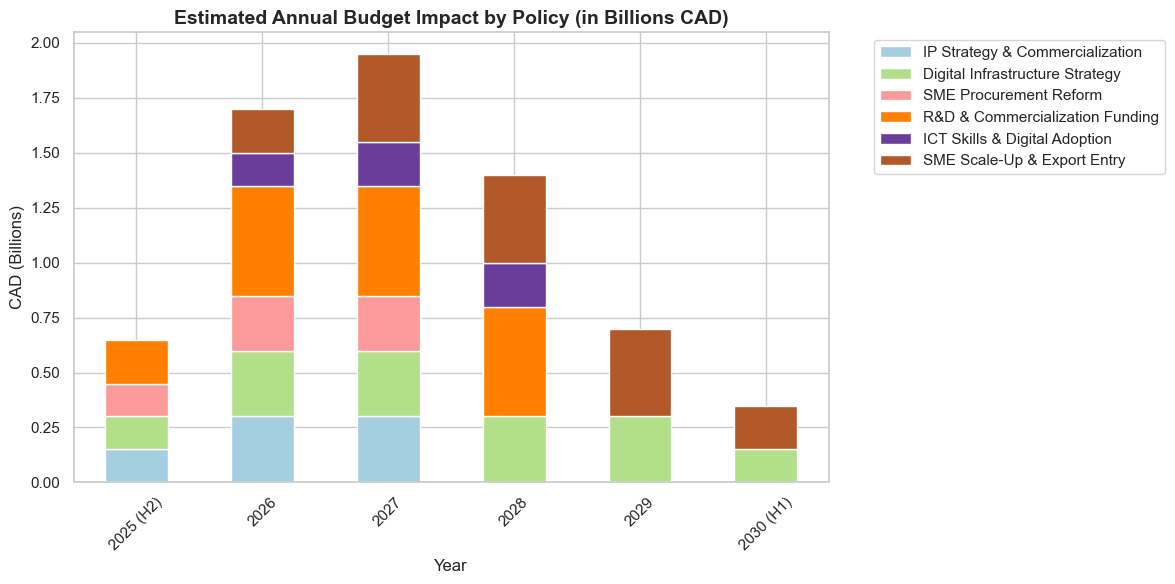

In [18]:
# Annual budget data (in millions CAD)
data = {
    'Year': ['2025 (H2)', '2026', '2027', '2028', '2029', '2030 (H1)'],
    'IP Strategy & Commercialization': [150, 300, 300, 0, 0, 0],
    'Digital Infrastructure Strategy': [150, 300, 300, 300, 300, 150],
    'SME Procurement Reform': [150, 250, 250, 0, 0, 0],
    'R&D & Commercialization Funding': [200, 500, 500, 500, 0, 0],
    'ICT Skills & Digital Adoption': [0, 150, 200, 200, 0, 0],
    'SME Scale-Up & Export Entry': [0, 200, 400, 400, 400, 200],
}

# Convert to DataFrame
df = pd.DataFrame(data)
df.set_index('Year', inplace=True)

# Convert values to billions for visual clarity
df_billion = df / 1000

# Plot settings
fig, ax = plt.subplots(figsize=(12, 6))
df_billion.plot(kind='bar', stacked=True, ax=ax, colormap='Paired')

# Customizations
plt.title("Estimated Annual Budget Impact by Policy (in Billions CAD)", fontsize=14, weight='bold')
plt.ylabel("CAD (Billions)")
plt.xlabel("Year")
plt.xticks(rotation=45)
plt.legend(title="", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

plt.show()

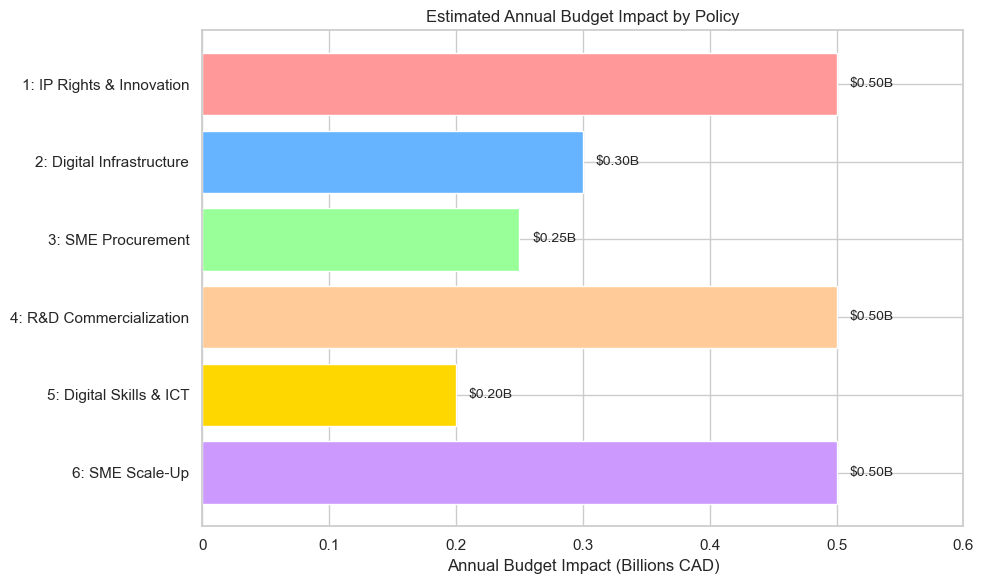

In [19]:
# Data: Estimated Annual Budget Impact by Policy (in Millions CAD)
policies = [
    "1: IP Rights & Innovation",
    "2: Digital Infrastructure",
    "3: SME Procurement",
    "4: R&D Commercialization",
    "5: Digital Skills & ICT",
    "6: SME Scale-Up"
]

annual_costs = [500, 300, 250, 500, 200, 500]  # In millions CAD

# Plotting
plt.figure(figsize=(10, 6))
bars = plt.barh(policies, annual_costs, color=['#FF9999', '#66B3FF', '#99FF99', '#FFCC99', '#FFD700', '#CC99FF'])
plt.xlabel("Annual Budget Impact (Billions CAD)")
plt.title("Estimated Annual Budget Impact by Policy")

# Format x-axis in billions
plt.xticks([0, 100, 200, 300, 400, 500, 600], ['0', '0.1', '0.2', '0.3', '0.4', '0.5', '0.6'])

# Add labels
for bar in bars:
    width = bar.get_width()
    plt.text(width + 10, bar.get_y() + bar.get_height() / 2,
             f"${width/1000:.2f}B", va='center', ha='left', fontsize=10)

plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


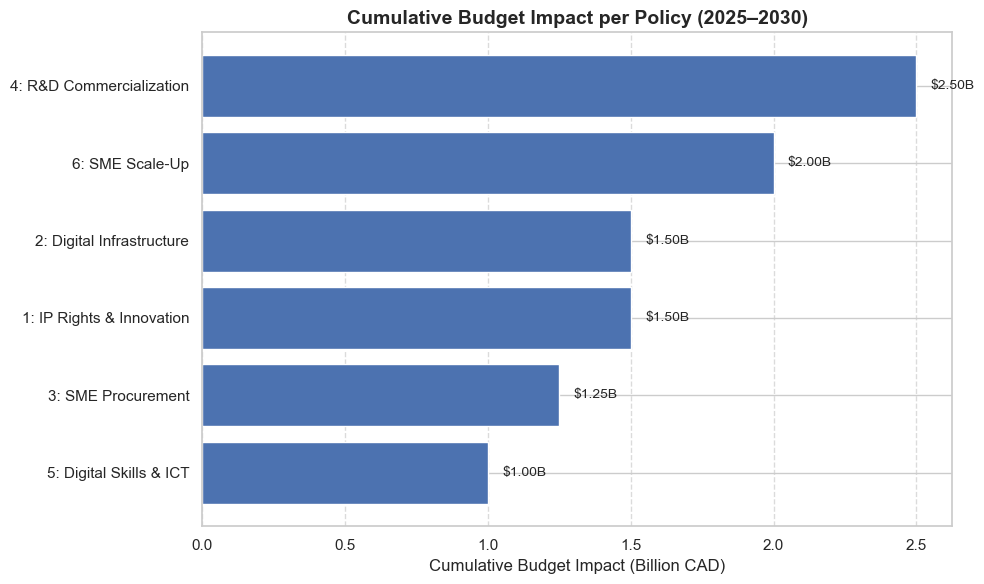

In [20]:
# Define data: cumulative cost over 5 years for each policy
policies = [
    "1: IP Rights & Innovation", "2: Digital Infrastructure", 
    "3: SME Procurement", "4: R&D Commercialization", 
    "5: Digital Skills & ICT", "6: SME Scale-Up"
]
cumulative_costs = [1.5, 1.5, 1.25, 2.5, 1.0, 2.0]  # in billions CAD

# Create DataFrame
df = pd.DataFrame({
    "Policy": policies,
    "Cumulative Cost (Billion CAD)": cumulative_costs
})

# Sort for visual impact
df = df.sort_values("Cumulative Cost (Billion CAD)", ascending=True)

# Plot
plt.figure(figsize=(10, 6))
bars = plt.barh(df["Policy"], df["Cumulative Cost (Billion CAD)"], color="#4C72B0")
plt.xlabel("Cumulative Budget Impact (Billion CAD)", fontsize=12)
plt.title("Cumulative Budget Impact per Policy (2025–2030)", fontsize=14, weight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Annotate bars
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.05, bar.get_y() + bar.get_height()/2,
             f"${width:.2f}B", va='center', fontsize=10)

plt.tight_layout()
plt.show()


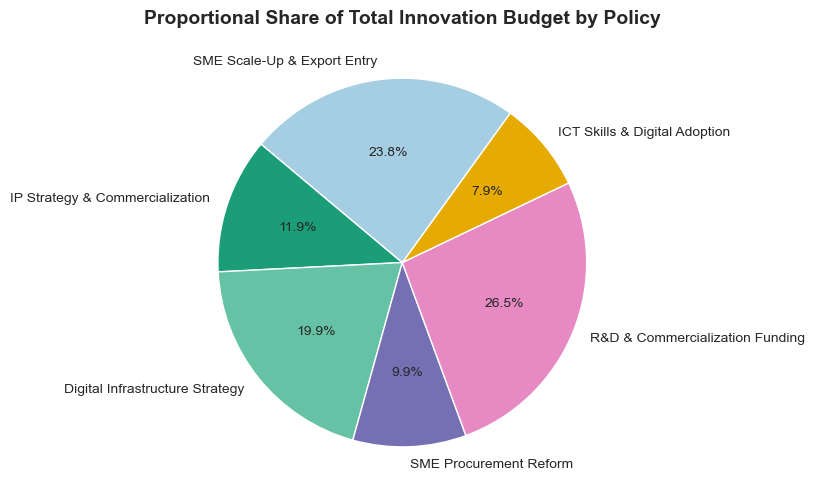

In [21]:
# Define data for each policy (in millions CAD)
policy_labels = [
    "IP Strategy & Commercialization",
    "Digital Infrastructure Strategy",
    "SME Procurement Reform",
    "R&D & Commercialization Funding",
    "ICT Skills & Digital Adoption",
    "SME Scale-Up & Export Entry"
]

# Corresponding total budget values across years (in millions)
policy_totals = [900, 1500, 750, 2000, 600, 1800]

# Define custom colors
colors = [
    "#1b9e77",  # IP Strategy & Commercialization
    "#66c2a5",  # Digital Infrastructure Strategy
    "#7570b3",  # SME Procurement Reform
    "#e78ac3",  # R&D & Commercialization Funding
    "#e6ab02",  # ICT Skills & Digital Adoption
    "#a6cee3"   # SME Scale-Up & Export Entry
]

# Plot the pie chart
fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(
    policy_totals,
    labels=policy_labels,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    textprops={'fontsize': 10}
)

# Format the chart
ax.set_title("Proportional Share of Total Innovation Budget by Policy", fontsize=14, weight='bold')
plt.tight_layout()
plt.show()


# Comparative Budget Allocation: Canada vs. Top Performers  

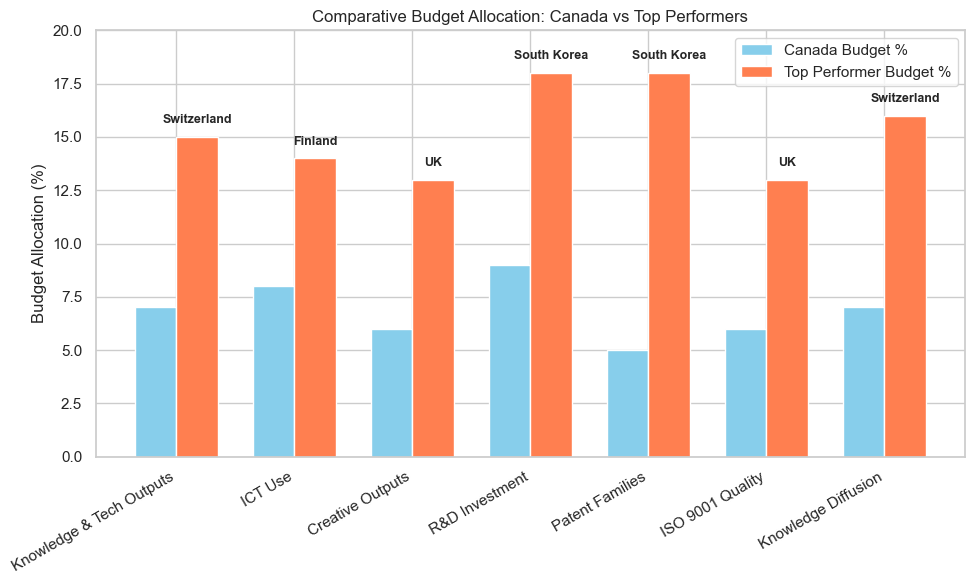

In [23]:
# Innovation areas
innovation_areas = [
    "Knowledge & Tech Outputs", "ICT Use", "Creative Outputs",
    "R&D Investment", "Patent Families", "ISO 9001 Quality",
    "Knowledge Diffusion"
]

# Budget allocations (%)
canada_budget = [7, 8, 6, 9, 5, 6, 7]
top_performer_budget = [15, 14, 13, 18, 18, 13, 16]

# Top-performing countries per innovation area
top_countries = [
    "Switzerland", "Finland", "UK",
    "South Korea", "South Korea", "UK", "Switzerland"
]

x = np.arange(len(innovation_areas))
width = 0.35  # Bar width

# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, canada_budget, width, label='Canada Budget %', color='skyblue')
bars2 = ax.bar(x + width/2, top_performer_budget, width, label='Top Performer Budget %', color='coral')

# Add country labels above the top performer bars
for idx, bar in enumerate(bars2):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 0.5, top_countries[idx],
            ha='center', va='bottom', fontsize=9, fontweight='bold')

# Labels and titles
ax.set_ylabel('Budget Allocation (%)')
ax.set_title('Comparative Budget Allocation: Canada vs Top Performers')
ax.set_xticks(x)
ax.set_xticklabels(innovation_areas, rotation=30, ha='right')
ax.set_ylim(0, 20)
ax.legend()

plt.tight_layout()
plt.show()


# Canada’s Innovation KPI Growth Targets (2025–2030)

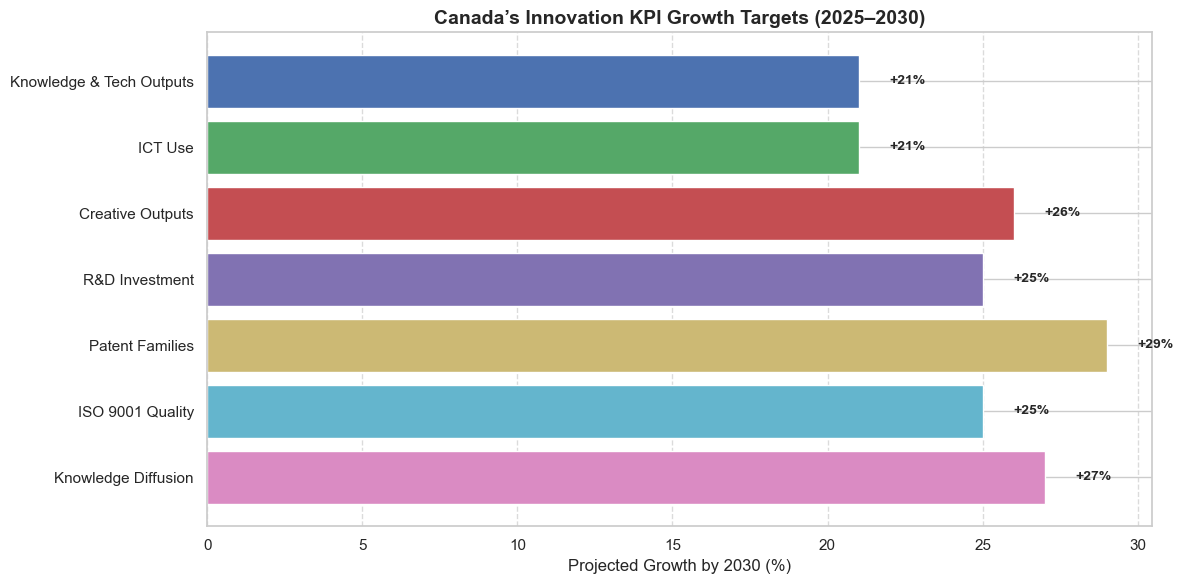

In [25]:
# Define the KPI names and their corresponding growth percentages
kpi_labels = [
    "Knowledge & Tech Outputs",
    "ICT Use",
    "Creative Outputs",
    "R&D Investment",
    "Patent Families",
    "ISO 9001 Quality",
    "Knowledge Diffusion"
]

kpi_growth = [21, 21, 26, 25, 29, 25, 27]

# Set color palette
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974', '#64B5CD', '#DA8BC3']

# Plotting
plt.figure(figsize=(12, 6))
bars = plt.barh(kpi_labels, kpi_growth, color=colors)
plt.xlabel("Projected Growth by 2030 (%)")
plt.title("Canada’s Innovation KPI Growth Targets (2025–2030)", fontsize=14, weight='bold')
plt.gca().invert_yaxis()  # Highest bar on top
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Annotate values
for bar in bars:
    width = bar.get_width()
    plt.text(width + 1, bar.get_y() + bar.get_height()/2,
             f"+{int(width)}%", va='center', ha='left', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


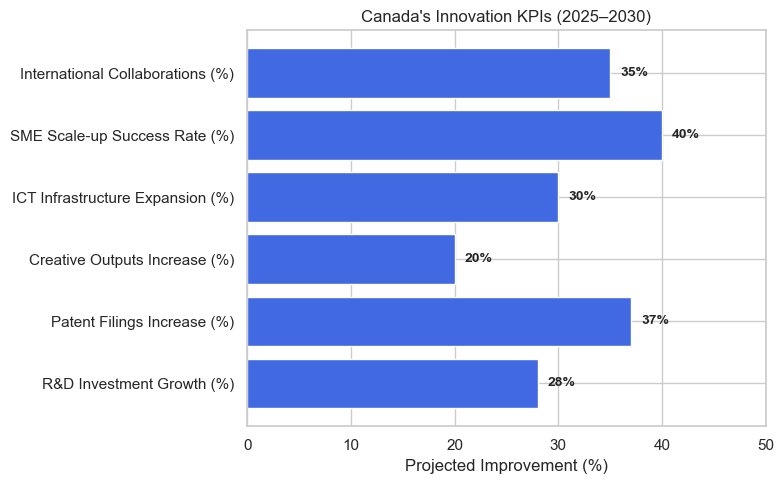

In [26]:
# KPI categories and projected improvements
kpis = [
    "International Collaborations (%)",
    "SME Scale-up Success Rate (%)",
    "ICT Infrastructure Expansion (%)",
    "Creative Outputs Increase (%)",
    "Patent Filings Increase (%)",
    "R&D Investment Growth (%)"
]

improvements = [35, 40, 30, 20, 37, 28]

# Plot setup
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(kpis, improvements, color='royalblue')

# Add data labels to bars
for bar in bars:
    width = bar.get_width()
    ax.text(width + 1, bar.get_y() + bar.get_height()/2, f'{int(width)}%', 
            va='center', fontsize=10, fontweight='bold')

# Axis labels and title
ax.set_xlabel('Projected Improvement (%)')
ax.set_title("Canada's Innovation KPIs (2025–2030)")
ax.set_xlim(0, 50)
plt.gca().invert_yaxis()  # Highest improvement on top

plt.tight_layout()
plt.show()
